# Δlog CAPE — EDA

Exploration of the annual valuation change `dlcape` $= \Delta\log \text{CAPE}$ and its relation to the ISSM macro building blocks (plan: `delta_cape_eda.md`).

**Goal:** decide how `dlcape` should be treated in the scenarios:

1. as i.i.d. noise around zero: the current ISSM treatment. `load_shiller_annual` builds `erp = xr − mean(dlcape)`, so only the average re-rating is removed and the year-to-year re-rating stays in erp, bootstrapped jointly with the macro shocks of the same year;
2. as a function of the contemporaneous macro state (π, r, tp, fr), kept through the joint bootstrap;
3. as predictable / mean-reverting through the CAPE level, which would need a model term.

All series are annual log returns, Dec→Dec, 1935–2025, in **percent** (as in `issm_eda.ipynb`). `logcape` $= 100\log\text{CAPE}$ is on the same scale, so that $\Delta$`logcape` = `dlcape` and its regression coefficient is in pp per pp.

## Setup

In [1]:
import Pkg
Pkg.activate(joinpath(@__DIR__, ".."))

using MacroFinanceScenarios
using MacroFinanceScenarios.IbbotsonSinquefield
using MacroFinanceScenarios.EDA
using CSV, DataFrames, Dates, LinearAlgebra, Statistics, StatsBase, TimeSeries
using Distributions: Chisq, FDist, TDist, ccdf
using Plots, StatsPlots

# Render the EDA tables as HTML in the notebook.
show_table(t; title = "", digits = 2) =
    display(HTML(sprint(io -> print_table(io, t; backend = :html, digits, title))))

  Activating project at `~/projects/MacroFinanceScenarios`
[ Info: Precompiling MacroFinanceScenarios [855219de-e5b9-4c44-9d68-0e4839ca4f75] (cache misses: wrong dep version loaded (6), wrong source (2), mismatched flags (12))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling IJuliaExt [2f4121a4-3b3a-5ce6-9c5e-1f2673ce16

show_table (generic function with 1 method)

## 1. Load data

Annual series from `data/shiller_annual.csv` (written by `export_shiller_annual.jl`; see `issm_eda.ipynb` for the definitions):

- `dlcape`  valuation change $\Delta\log\text{CAPE}_t$, the target
- `π`       inflation
- `r`       ex-post real short rate `rf − π`
- `tp`      term spread (10y yield − T-bill yield) at the **start** of the year, i.e. known at $t-1$
- `fr`      fundamental return `re − dlcape` (nominal)
- `fr_real` real fundamental return `fr − π`
- `logcape` $100\log\text{CAPE}_t$ (level)

**Caveats** (they shape how the regressions are read):

- `fr` is mechanically tied to `dlcape`: `fr ≡ re − dlcape`. Roughly $fr \approx$ dividend yield $+\ \pi + \Delta\log(\text{10y-avg real earnings})$ while $dlcape = \Delta\log\text{real price} - \Delta\log(\text{10y-avg real earnings})$, so the earnings-growth term enters both with opposite signs and part of their negative correlation is built in.
- `fr` is nominal and strongly correlated with π; `fr_real` removes that.
- `r = rf − π` contains $-\pi$, so π and r are mechanically negatively correlated: expect collinearity in the joint regression.
- Same-year regressors (π, r, fr) *explain* `dlcape` but are not known in advance; `tp`, `logcape_lag` and `dlcape_lag` are *predictive*.

In [2]:
raw = TimeArray(CSV.File(joinpath(@__DIR__, "..", "data", "shiller_annual.csv")); timestamp = :timestamp)
col(ta, name) = vec(values(ta[name]))

π_, r_, tp_, fr_ = (100 .* col(raw, v) for v in (:π, :r, :tp, :fr))
dlcape_ = 100 .* col(raw, :dlcape)
logcape_ = 100 .* log.(col(raw, :cape))

data = TimeArray(timestamp(raw),
                 hcat(dlcape_, π_, r_, tp_, fr_, fr_ .- π_, logcape_),
                 [:dlcape, :π, :r, :tp, :fr, :fr_real, :logcape])

# Same columns plus their one-year lags; the first year (1935) is lost to the lag.
# Used for every regression, so contemporaneous and predictive fits share the same years.
lag_vars = [:dlcape, :π, :r, :tp, :fr, :fr_real, :logcape]
data_lag = TimeArray(timestamp(data)[2:end],
                     hcat(values(data)[2:end, :], values(data[lag_vars...])[1:end-1, :]),
                     [colnames(data); Symbol.(lag_vars, :_lag)])
first(DataFrame(data_lag), 5)

Row,timestamp,dlcape,π,r,tp,fr,fr_real,logcape,dlcape_lag,π_lag,r_lag,tp_lag,fr_lag,fr_real_lag,logcape_lag
,Date,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,1936-12-31,26.7999,1.43887,-1.28899,2.35427,3.38173,1.94285,305.049,32.8099,2.94139,-2.71165,3.74749,4.80225,1.86086,278.249
2,1937-12-31,-48.4887,2.81709,-2.69716,3.35534,11.6532,8.83615,256.56,26.7999,1.43887,-1.28899,2.35427,3.38173,1.94285,305.049
3,1938-12-31,19.165,-2.81709,2.92703,3.93533,0.289708,3.1068,275.725,-48.4887,2.81709,-2.69716,3.35534,11.6532,8.83615,256.56
4,1939-12-31,3.27107,0.0,0.0299955,3.53368,-1.48775,-1.48775,278.996,19.165,-2.81709,2.92703,3.93533,0.289708,3.1068,275.725
5,1940-12-31,-15.7468,0.711747,-0.671755,4.15266,5.63947,4.92772,263.249,3.27107,0.0,0.0299955,3.53368,-1.48775,-1.48775,278.996


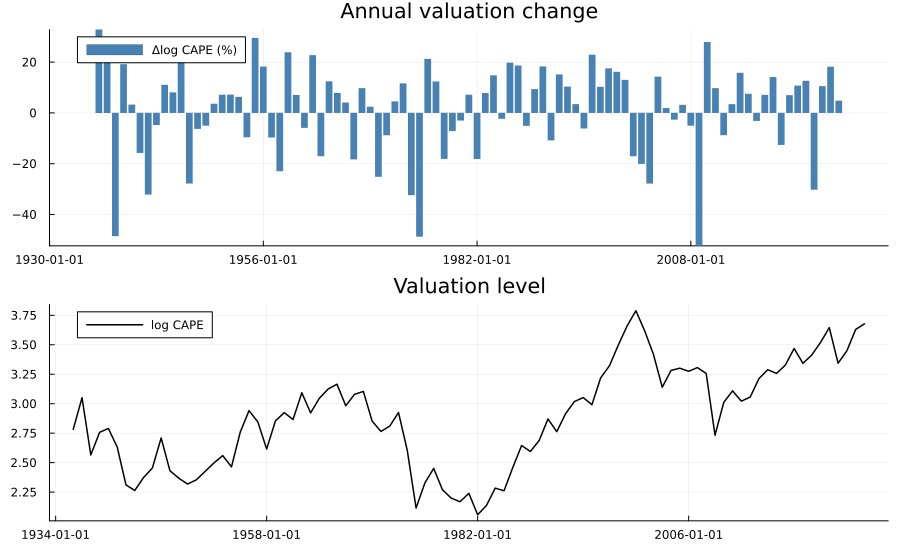

In [3]:
p1 = bar(timestamp(data), col(data, :dlcape); label = "Δlog CAPE (%)", lw = 0, color = :steelblue,
         title = "Annual valuation change")
p2 = plot(data[:logcape] ./ 100; label = "log CAPE", lw = 1.5, color = :black, title = "Valuation level")
plot(p1, p2; layout = (2, 1), size = (900, 550), legend = :topleft)

## 2. Sample periods

The same periods as in `issm_eda.ipynb`, so the results line up with the ISSM specs. The regressions (sections 6–7) use `data_lag`, which starts in 1936.

In [4]:
periods = [
    :full     => (1935, 2025),
    :pre1975  => (1935, 1974),
    :post1975 => (1975, 2025),
]
span(ta) = "$(year(timestamp(ta)[1]))–$(year(timestamp(ta)[end]))"

span (generic function with 1 method)

## 3. Moments of dlcape

`t_mean` $=\bar x / (s/\sqrt n)$ tests whether the average re-rating differs from zero (i.i.d. approximation). `ar1` is the lag-1 autocorrelation (significant beyond $\pm 1.96/\sqrt n$).

In [5]:
moments = vcat([begin
    sub = subperiod(data, p)[:dlcape]
    x = col(sub, :dlcape)
    d = describe_series(sub)
    insertcols!(d, 2, :period => String(name), :years => span(sub), :n => length(x),
                :t_mean => mean(x) / (std(x) / sqrt(length(x))), :band => 1.96 / sqrt(length(x)))
end for (name, p) in periods]...)
show_table(moments; title = "Moments of Δlog CAPE (%)")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"17\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Moments of Δlog CAPE (%)</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">variable</th>\n      <th style = \"font-weight: bold; text-align: right;\">period</th>\n      <th style = \"font-weight: bold; text-align: right;\">years</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">t_mean</th>\n      <th style = \"font-weight: bold; text-align: right;\">band</th>\n      <th style = \"font-weight: bold; text-align: right;\">mean</th>\n      <th style = \"font-weight: bold; text-align: right;\">std</th>\n      <th style = \"font-weight: bold; text-align: right;\">skewness</th>\n      <th style = \"font-weight: bold; text-align: right;\">ex_kurtosis</th>\n      <th style = \"font-weight: bold; text-align: right;\">ar1</th>\n      <th style = \"font-weight: bold; text-align: right;\">neg</th>\n      <th style = \"font-weight: bold; text-align: right;\">min</th>\n      <th style = \"font-weight: bold; text-align: right;\">p25</th>\n      <th style = \"font-weight: bold; text-align: right;\">p50</th>\n      <th style = \"font-weight: bold; text-align: right;\">p75</th>\n      <th style = \"font-weight: bold; text-align: right;\">max</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">1935–2025</td>\n      <td style = \"text-align: right;\">91.0</td>\n      <td style = \"text-align: right;\">0.72</td>\n      <td style = \"text-align: right;\">0.21</td>\n      <td style = \"text-align: right;\">1.34</td>\n      <td style = \"text-align: right;\">17.75</td>\n      <td style = \"text-align: right;\">-0.89</td>\n      <td style = \"text-align: right;\">0.66</td>\n      <td style = \"text-align: right;\">-0.06</td>\n      <td style = \"text-align: right;\">38.46</td>\n      <td style = \"text-align: right;\">-52.36</td>\n      <td style = \"text-align: right;\">-7.93</td>\n      <td style = \"text-align: right;\">6.28</td>\n      <td style = \"text-align: right;\">12.79</td>\n      <td style = \"text-align: right;\">32.81</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">1935–1974</td>\n      <td style = \"text-align: right;\">40.0</td>\n      <td style = \"text-align: right;\">-0.27</td>\n      <td style = \"text-align: right;\">0.31</td>\n      <td style = \"text-align: right;\">-0.85</td>\n      <td style = \"text-align: right;\">20.22</td>\n      <td style = \"text-align: right;\">-0.57</td>\n      <td style = \"text-align: right;\">-0.17</td>\n      <td style = \"text-al

The largest re-ratings, with the same-year macro state. Crisis and recovery years dominate the tails.

In [6]:
years_df = DataFrame(data_lag[:dlcape, :π, :r, :tp, :fr, :logcape_lag])
years_df.year = year.(years_df.timestamp)
largest = first(sort(select(years_df, :year, Not(:timestamp, :year)), :dlcape; by = abs, rev = true), 10)
show_table(largest; title = "Ten largest |Δlog CAPE| years", digits = 1)

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"7\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Ten largest |Δlog CAPE| years</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">year</th>\n      <th style = \"font-weight: bold; text-align: right;\">dlcape</th>\n      <th style = \"font-weight: bold; text-align: right;\">π</th>\n      <th style = \"font-weight: bold; text-align: right;\">r</th>\n      <th style = \"font-weight: bold; text-align: right;\">tp</th>\n      <th style = \"font-weight: bold; text-align: right;\">fr</th>\n      <th style = \"font-weight: bold; text-align: right;\">logcape_lag</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">2008.0</td>\n      <td style = \"text-align: right;\">-52.4</td>\n      <td style = \"text-align: right;\">0.1</td>\n      <td style = \"text-align: right;\">2.9</td>\n      <td style = \"text-align: right;\">13.3</td>\n      <td style = \"text-align: right;\">3.3</td>\n      <td style = \"text-align: right;\">325.6</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">1974.0</td>\n      <td style = \"text-align: right;\">-48.7</td>\n      <td style = \"text-align: right;\">11.6</td>\n      <td style = \"text-align: right;\">-4.4</td>\n      <td style = \"text-align: right;\">-4.9</td>\n      <td style = \"text-align: right;\">19.3</td>\n      <td style = \"text-align: right;\">260.2</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">1937.0</td>\n      <td style = \"text-align: right;\">-48.5</td>\n      <td style = \"text-align: right;\">2.8</td>\n      <td style = \"text-align: right;\">-2.7</td>\n      <td style = \"text-align: right;\">3.4</td>\n      <td style = \"text-align: right;\">11.7</td>\n      <td style = \"text-align: right;\">305.0</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">1973.0</td>\n      <td style = \"text-align: right;\">-32.3</td>\n      <td style = \"text-align: right;\">8.3</td>\n      <td style = \"text-align: right;\">-3.4</td>\n      <td style = \"text-align: right;\">-1.2</td>\n      <td style = \"text-align: right;\">14.2</td>\n      <td style = \"text-align: right;\">292.6</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">1941.0</td>\n      <td style = \"text-align: right;\">-32.1</td>\n      <td style = \"text-align: right;\">9.5</td>\n      <td style = \"text-align: right;\">-9.4</td>\n      <td style = \"text-align: right;\">-1.6</td>\n      <td style = \"text-align: right;\">21.3</td>\n      <td style = \"text-align: right;\">263.2</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">2022.0</td>\n      <td style = \"text-align: right;\">-30.2</td>\n      <td style = \"text-align: right;\">6.3</td>\n      <td style = \"text-align: right;\">-6.2</td>\n      <td style = \"text-align: right;\">-16.2</td>\n      <td style = \"text-align: right;\">14.0</td>\n      <td style = \"text-align: right;\">364.6</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">1954.0</td>\n      <td style = \"text-align: right;\">29.5</td>\n      <td style = \"text-align: right;\">-0.7</td>\n      <td style = \"text-align: right;\">2.3</td>\n      <td style = \"text-align: right;\">1.6</td>\n      <td style = \"text-align: right;\">8.9</td>\n      <t

## 4. Correlations

Correlation of `dlcape_t` with each regressor, contemporaneous ($x_t$) and lagged ($x_{t-1}$), on `data_lag` so all cells of a period share the same years. $|\rho| >$ band $= 1.96/\sqrt n$ is significant at 5%.

In [7]:
contemp_regs = [:π, :r, :tp, :fr, :fr_real]
lagged_regs = [:π_lag, :r_lag, :tp_lag, :fr_lag, :fr_real_lag, :logcape_lag, :dlcape_lag]

corr_rows = [(timing, v) for (timing, vs) in (("contemporaneous", contemp_regs), ("lagged", lagged_regs)) for v in vs]
corr_table = DataFrame([(; regressor = String(v), timing,
                           (name => cor(col(subperiod(data_lag, p), :dlcape), col(subperiod(data_lag, p), v))
                            for (name, p) in periods)...)
                        for (timing, v) in corr_rows])
bands = join(["$name ±$(round(1.96 / sqrt(length(subperiod(data_lag, p))); digits = 2))" for (name, p) in periods], ", ")
show_table(corr_table; title = "corr(dlcape_t, x) — 5% bands: $bands")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"5\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">corr(dlcape_t, x) — 5% bands: full ±0.21, pre1975 ±0.31, post1975 ±0.27</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">regressor</th>\n      <th style = \"font-weight: bold; text-align: right;\">timing</th>\n      <th style = \"font-weight: bold; text-align: right;\">full</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">contemporaneous</td>\n      <td style = \"text-align: right;\">-0.38</td>\n      <td style = \"text-align: right;\">-0.59</td>\n      <td style = \"text-align: right;\">-0.1</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">contemporaneous</td>\n      <td style = \"text-align: right;\">0.32</td>\n      <td style = \"text-align: right;\">0.43</td>\n      <td style = \"text-align: right;\">0.13</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">contemporaneous</td>\n      <td style = \"text-align: right;\">0.09</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.08</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr</td>\n      <td style = \"text-align: right;\">contemporaneous</td>\n      <td style = \"text-align: right;\">-0.41</td>\n      <td style = \"text-align: right;\">-0.55</td>\n      <td style = \"text-align: right;\">-0.21</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr_real</td>\n      <td style = \"text-align: right;\">contemporaneous</td>\n      <td style = \"text-align: right;\">-0.21</td>\n      <td style = \"text-align: right;\">-0.17</td>\n      <td style = \"text-align: right;\">-0.2</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π_lag</td>\n      <td style = \"text-align: right;\">lagged</td>\n      <td style = \"text-align: right;\">-0.09</td>\n      <td style = \"text-align: right;\">-0.12</td>\n      <td style = \"text-align: right;\">-0.09</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r_lag</td>\n      <td style = \"text-align: right;\">lagged</td>\n      <td style = \"text-align: right;\">0.12</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.12</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp_lag</td>\n      <td style = \"text-align: right;\">lagged</td>\n      <td style = \"text-align: right;\">0.12</td>\n      <td style = \"text-align: right;\">0.28</td>\n      <td style = \"text-align: right;\">0.06</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr_lag</td>\n      <td style = \"text-align: right;\">lagged</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.11</td>\n      <td style = \"text-align: right;\">-0.08</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr_real_lag</td>\n      <td style = \"text-align: right;\">lagged</td>\n      <td style = \"text-align: right;\">0.09</td>\n      <td style

## 5. Moving averages

Trailing 10y and 20y means (the first 9/19 years are missing). A long-run mean far from zero for decades would be a persistent valuation drift that an i.i.d. bootstrap of `dlcape` would extrapolate. The lower panel shows the trailing 20y standard deviation, to check whether the volatility is stable.

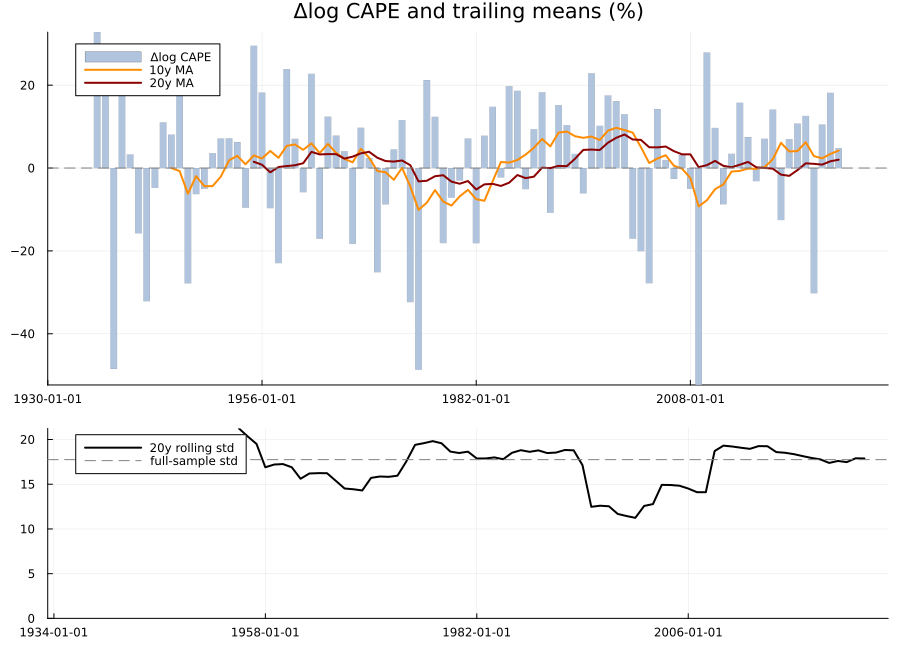

In [8]:
trailing(f, x, w) = [i < w ? NaN : f(x[i-w+1:i]) for i in eachindex(x)]

dl = col(data, :dlcape)
ts = timestamp(data)
pa = bar(ts, dl; label = "Δlog CAPE", lw = 0, color = :lightsteelblue, title = "Δlog CAPE and trailing means (%)")
plot!(pa, ts, trailing(mean, dl, 10); label = "10y MA", lw = 2, color = :darkorange)
plot!(pa, ts, trailing(mean, dl, 20); label = "20y MA", lw = 2, color = :darkred)
hline!(pa, [0]; color = :gray, ls = :dash, label = "")
pb = plot(ts, trailing(std, dl, 20); label = "20y rolling std", lw = 2, color = :black, ylims = (0, Inf))
hline!(pb, [std(dl)]; color = :gray, ls = :dash, label = "full-sample std")
plot(pa, pb; layout = grid(2, 1; heights = [0.65, 0.35]), size = (900, 650), legend = :topleft)

## 6. Stationarity

Both `dlcape` and the level `logcape` are tested; the level test decides whether a mean-reversion term in `logcape_lag` is defensible.

- **ADF** with a constant: $\Delta y_t = \alpha + \delta\, y_{t-1} + \sum_{j=1}^{p}\gamma_j \Delta y_{t-j} + e_t$, H0: unit root ($\delta = 0$). $p \le 4$ chosen by BIC on a common sample. Critical values from the MacKinnon (2010) response surface for the sample size.
- **KPSS** (level), H0: stationary. Long-run variance with a Bartlett kernel and bandwidth $\lfloor 4 (n/100)^{1/4} \rfloor$; 5% critical value 0.463.

The two tests have opposite nulls; with ~40–90 years both have low power, so "neither rejects" is a likely outcome for the level.

In [9]:
# MacKinnon (2010), constant, no trend: cv(T) = b∞ + b1/T + b2/T² + b3/T³
const ADF_CV = Dict(0.01 => (-3.43035, -6.5393, -16.786, -79.433),
                    0.05 => (-2.86154, -2.8903, -4.234, -40.040),
                    0.10 => (-2.56677, -1.5384, -2.809, 0.0))
adf_cv(T, level = 0.05) = (b = ADF_CV[level]; b[1] + b[2] / T + b[3] / T^2 + b[4] / T^3)

function adf_test(y; max_lags = 4)
    dy = diff(y)
    n = length(dy)
    fits = map(0:max_lags) do p
        rows = (max_lags + 1):n                     # common sample for the BIC comparison
        X = hcat(ones(length(rows)), y[rows], (dy[rows .- j] for j in 1:p)...)
        z = dy[rows]
        β = X \ z
        e = z - X * β
        bic = length(z) * log(sum(abs2, e) / length(z)) + size(X, 2) * log(length(z))
        (p = p, bic = bic)
    end
    p = fits[argmin([f.bic for f in fits])].p
    rows = (p + 1):n                                # refit on the longest sample for the chosen p
    X = hcat(ones(length(rows)), y[rows], (dy[rows .- j] for j in 1:p)...)
    z = dy[rows]
    β = X \ z
    e = z - X * β
    σ² = sum(abs2, e) / (length(z) - size(X, 2))
    se = sqrt(σ² * inv(X' * X)[2, 2])
    return (stat = β[2] / se, lags = p, n = length(z), cv5 = adf_cv(length(z)))
end

bartlett_bandwidth(n) = floor(Int, 4 * (n / 100)^0.25)

function long_run_variance(e, L)
    n = length(e)
    γ(l) = sum(e[t] * e[t-l] for t in (l+1):n) / n
    return γ(0) + 2 * sum((1 - l / (L + 1)) * γ(l) for l in 1:L; init = 0.0)
end

function kpss_test(y)
    n = length(y)
    e = y .- mean(y)
    S = cumsum(e)
    L = bartlett_bandwidth(n)
    return (stat = sum(abs2, S) / (n^2 * long_run_variance(e, L)), bandwidth = L, cv5 = 0.463)
end

stationarity = DataFrame([begin
    y = col(subperiod(data, p), var)
    adf = adf_test(y)
    kpss = kpss_test(y)
    (series = String(var), period = String(name), n = length(y),
     adf_lags = adf.lags, adf = adf.stat, adf_cv5 = adf.cv5,
     adf_result = adf.stat < adf.cv5 ? "reject unit root" : "unit root not rejected",
     kpss = kpss.stat, kpss_cv5 = kpss.cv5,
     kpss_result = kpss.stat > kpss.cv5 ? "reject stationarity" : "stationarity not rejected")
end for var in (:dlcape, :logcape) for (name, p) in periods])
show_table(stationarity; title = "Stationarity tests (5%)")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"10\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Stationarity tests (5%)</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">series</th>\n      <th style = \"font-weight: bold; text-align: right;\">period</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">adf_lags</th>\n      <th style = \"font-weight: bold; text-align: right;\">adf</th>\n      <th style = \"font-weight: bold; text-align: right;\">adf_cv5</th>\n      <th style = \"font-weight: bold; text-align: right;\">adf_result</th>\n      <th style = \"font-weight: bold; text-align: right;\">kpss</th>\n      <th style = \"font-weight: bold; text-align: right;\">kpss_cv5</th>\n      <th style = \"font-weight: bold; text-align: right;\">kpss_result</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">String</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">91.0</td>\n      <td style = \"text-align: right;\">1.0</td>\n      <td style = \"text-align: right;\">-9.31</td>\n      <td style = \"text-align: right;\">-2.89</td>\n      <td style = \"text-align: right;\">reject unit root</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.46</td>\n      <td style = \"text-align: right;\">stationarity not rejected</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">40.0</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">-6.03</td>\n      <td style = \"text-align: right;\">-2.94</td>\n      <td style = \"text-align: right;\">reject unit root</td>\n      <td style = \"text-align: right;\">0.26</td>\n      <td style = \"text-align: right;\">0.46</td>\n      <td style = \"text-align: right;\">stationarity not rejected</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape</td>\n      <td style = \"text-align: right;\">post1975</td>\n      <td style = \"text-align: right;\">51.0</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">-7.33</td>\n      <td style = \"text-align: right;\">-2.92</td>\n      <td style = \"text-align: right;\">reject unit root</td>\n      <td style = \"text-align: right;\">0.1</td>\n      <td style = \"text-align: right;\">0.46</td>\n      <td style = \"text-align: right;\">stationarity not rejected</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">logcape</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">91.0</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">-1.5</td>\n      <td style = \"text-align: right;\">-2.89</td>\n      <td style = \"text-align: right;\">unit root not rejected</td>\n      <td style = \"text-align: right;\">1.13</td>\n      <td style = \"text-align: right;\">0.46</td>\n      <td style = \"text-align: right;\">reject stationarity</td>\n    </tr>\n    <tr cl

## 7. Regression helpers

OLS with `X \ y` and Newey–West (HAC) standard errors with 2 lags (Bartlett weights, small-sample factor $n/(n-k)$). Annual residuals are not overlapping, but they are heteroskedastic (crisis years), so HAC errors are used for all t-tests and Wald tests.

In [10]:
function newey_west(X, e, L)
    n, k = size(X)
    S = zeros(k, k)
    for t in 1:n
        S .+= e[t]^2 .* (X[t, :] * X[t, :]')
    end
    for l in 1:L, t in (l+1):n
        G = e[t] * e[t-l] .* (X[t, :] * X[t-l, :]')
        S .+= (1 - l / (L + 1)) .* (G .+ G')
    end
    B = inv(X' * X)
    return B * S * B .* (n / (n - k))
end

"""OLS of `dlcape` on `regs` (columns of `ta`, intercept added) with Newey–West covariance."""
function fit_ols(ta::TimeArray, regs::AbstractVector{Symbol}; y = :dlcape, nw_lags = 2)
    z = col(ta, y)
    X = hcat(ones(length(z)), (col(ta, r) for r in regs)...)
    n, k = size(X)
    β = X \ z
    e = z - X * β
    ssr = sum(abs2, e)
    r2 = 1 - ssr / sum(abs2, z .- mean(z))
    return (terms = [:const; regs], β = β, V = newey_west(X, e, nw_lags), resid = e, fitted = X * β,
            ssr = ssr, n = n, k = k, r2 = r2, adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k),
            σ = sqrt(ssr / (n - k)), years = year.(timestamp(ta)))
end

tstat(fit) = fit.β ./ sqrt.(diag(fit.V))
pvalue(fit) = 2 .* ccdf.(TDist(fit.n - fit.k), abs.(tstat(fit)))

"""HAC Wald test of `β[terms] = 0`, reported as F = W/q with F(q, n − k) p-value."""
function wald_test(fit, terms)
    idx = [findfirst(==(t), fit.terms) for t in terms]
    b = fit.β[idx]
    W = b' * (fit.V[idx, idx] \ b)
    q = length(idx)
    return (F = W / q, p = ccdf(FDist(q, fit.n - fit.k), W / q))
end

"""Nested (homoskedastic) partial F-test of the restricted vs. the unrestricted fit."""
function partial_f(unrestricted, restricted)
    q = unrestricted.k - restricted.k
    F = ((restricted.ssr - unrestricted.ssr) / q) / (unrestricted.ssr / (unrestricted.n - unrestricted.k))
    return (F = F, p = ccdf(FDist(q, unrestricted.n - unrestricted.k), F))
end

function ljung_box(x, h; fitted_params = 0)
    n = length(x)
    ρ = autocor(x, 1:h)
    Q = n * (n + 2) * sum(ρ[k]^2 / (n - k) for k in 1:h)
    return Q, ccdf(Chisq(h - fitted_params), Q)
end

ljung_box (generic function with 1 method)

## 8. Univariate regressions

$dlcape_t = a + b\, x + e_t$, one regressor at a time, on `data_lag` (1936–2025). `t_NW` uses Newey–West standard errors. The contemporaneous R² measures how much of the re-rating is *explained* by the same-year macro state; only `tp` and `logcape_lag` are known at the start of the year.

In [11]:
uni_regs = [:π, :r, :tp, :fr, :fr_real, :logcape_lag]
univariate = DataFrame([begin
    fit = fit_ols(subperiod(data_lag, p), [v])
    (regressor = String(v), period = String(name), n = fit.n, b = fit.β[2],
     t_NW = tstat(fit)[2], p_NW = pvalue(fit)[2], R² = fit.r2, adj_R² = fit.adj_r2)
end for v in uni_regs for (name, p) in periods])
show_table(univariate; title = "Univariate regressions of dlcape_t")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"8\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Univariate regressions of dlcape_t</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">regressor</th>\n      <th style = \"font-weight: bold; text-align: right;\">period</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">b</th>\n      <th style = \"font-weight: bold; text-align: right;\">t_NW</th>\n      <th style = \"font-weight: bold; text-align: right;\">p_NW</th>\n      <th style = \"font-weight: bold; text-align: right;\">R²</th>\n      <th style = \"font-weight: bold; text-align: right;\">adj_R²</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">90.0</td>\n      <td style = \"text-align: right;\">-2.1</td>\n      <td style = \"text-align: right;\">-3.68</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.14</td>\n      <td style = \"text-align: right;\">0.13</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">39.0</td>\n      <td style = \"text-align: right;\">-3.04</td>\n      <td style = \"text-align: right;\">-4.45</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.34</td>\n      <td style = \"text-align: right;\">0.33</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">post1975</td>\n      <td style = \"text-align: right;\">51.0</td>\n      <td style = \"text-align: right;\">-0.6</td>\n      <td style = \"text-align: right;\">-0.77</td>\n      <td style = \"text-align: right;\">0.45</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">-0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">90.0</td>\n      <td style = \"text-align: right;\">1.63</td>\n      <td style = \"text-align: right;\">3.25</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.1</td>\n      <td style = \"text-align: right;\">0.09</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">39.0</td>\n      <td style = \"text-align: right;\">2.09</td>\n      <td style = \"text-align: right;\">3.76</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.18</td>\n      <td style = \"text-align: right;\">0.16</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">post1975</td>\n      <td style = \"text-align: right;\">51.0</td>\n      <td style = \"text-align: right;\">0.71</td>\n      <td style = \"text-align: right;\">0.82</td>\n      <td style = \"text-align: right;\">0.41</td>\n      <td style = \"text-align: right;\">0

R² side by side (rows: regressor, columns: period).

In [12]:
show_table(unstack(univariate, :regressor, :period, :R²); title = "R² of the univariate regressions")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"4\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">R² of the univariate regressions</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">regressor</th>\n      <th style = \"font-weight: bold; text-align: right;\">full</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64?</th>\n      <th style = \"text-align: right;\">Float64?</th>\n      <th style = \"text-align: right;\">Float64?</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">0.14</td>\n      <td style = \"text-align: right;\">0.34</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">0.1</td>\n      <td style = \"text-align: right;\">0.18</td>\n      <td style = \"text-align: right;\">0.02</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr</td>\n      <td style = \"text-align: right;\">0.17</td>\n      <td style = \"text-align: right;\">0.3</td>\n      <td style = \"text-align: right;\">0.04</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr_real</td>\n      <td style = \"text-align: right;\">0.05</td>\n      <td style = \"text-align: right;\">0.03</td>\n      <td style = \"text-align: right;\">0.04</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">logcape_lag</td>\n      <td style = \"text-align: right;\">0.02</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.04</td>\n    </tr>\n  </tbody>\n</table>\n")

## 9. Joint regressions

- **Model A** (contemporaneous, explanatory): $dlcape_t = a + \beta_\pi \pi_t + \beta_r r_t + \beta_{tp} tp_t + \beta_{fr} fr_t + \rho\, dlcape_{t-1} + e_t$
- **Model B** (predictive only): $dlcape_t = a + \beta_{tp} tp_t + \gamma\, logcape_{t-1} + \rho\, dlcape_{t-1} + e_t$

$\gamma < 0$ means mean reversion of the valuation level: $\gamma = -0.1$ closes 10% of the gap to the long-run log CAPE each year.

In [13]:
models = [
    :A => [:π, :r, :tp, :fr, :dlcape_lag],
    :B => [:tp, :logcape_lag, :dlcape_lag],
]
macro_terms = Dict(:A => [:π, :r, :tp, :fr], :B => [:tp, :logcape_lag])
fits = Dict((m, name) => fit_ols(subperiod(data_lag, p), regs) for (m, regs) in models for (name, p) in periods)

Dict{Tuple{Symbol, Symbol}, @NamedTuple{terms::Vector{Symbol}, β::Vector{Float64}, V::Matrix{Float64}, resid::Vector{Float64}, fitted::Vector{Float64}, ssr::Float64, n::Int64, k::Int64, r2::Float64, adj_r2::Float64, σ::Float64, years::Vector{Int64}}} with 6 entries:
  (:B, :full)     => (terms = [:const, :tp, :logcape_lag, :dlcape_lag], β = [18…
  (:B, :post1975) => (terms = [:const, :tp, :logcape_lag, :dlcape_lag], β = [20…
  (:A, :full)     => (terms = [:const, :π, :r, :tp, :fr, :dlcape_lag], β = [13.…
  (:A, :post1975) => (terms = [:const, :π, :r, :tp, :fr, :dlcape_lag], β = [8.7…
  (:B, :pre1975)  => (terms = [:const, :tp, :logcape_lag, :dlcape_lag], β = [60…
  (:A, :pre1975)  => (terms = [:const, :π, :r, :tp, :fr, :dlcape_lag], β = [23.…

### Coefficients

Coefficients with Newey–West t-statistics in brackets, per period (the `pre1975` and `post1975` columns are the stability comparison).

In [14]:
for (m, regs) in models
    coef = DataFrame(term = String.([:const; regs]))
    for (name, _) in periods
        fit = fits[(m, name)]
        coef[!, "$(name)"] = fit.β
        coef[!, "$(name)_t"] = tstat(fit)
    end
    show_table(coef; title = "Model $m — coefficients and NW t-stats")
end

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"7\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Model A — coefficients and NW t-stats</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">term</th>\n      <th style = \"font-weight: bold; text-align: right;\">full</th>\n      <th style = \"font-weight: bold; text-align: right;\">full_t</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975_t</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975_t</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">const</td>\n      <td style = \"text-align: right;\">13.83</td>\n      <td style = \"text-align: right;\">3.81</td>\n      <td style = \"text-align: right;\">23.39</td>\n      <td style = \"text-align: right;\">2.7</td>\n      <td style = \"text-align: right;\">8.76</td>\n      <td style = \"text-align: right;\">2.13</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">-0.83</td>\n      <td style = \"text-align: right;\">-1.22</td>\n      <td style = \"text-align: right;\">-4.09</td>\n      <td style = \"text-align: right;\">-2.52</td>\n      <td style = \"text-align: right;\">0.52</td>\n      <td style = \"text-align: right;\">0.52</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">0.6</td>\n      <td style = \"text-align: right;\">1.28</td>\n      <td style = \"text-align: right;\">-2.3</td>\n      <td style = \"text-align: right;\">-1.59</td>\n      <td style = \"text-align: right;\">0.5</td>\n      <td style = \"text-align: right;\">0.71</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">-0.2</td>\n      <td style = \"text-align: right;\">-0.59</td>\n      <td style = \"text-align: right;\">-0.95</td>\n      <td style = \"text-align: right;\">-1.07</td>\n      <td style = \"text-align: right;\">0.03</td>\n      <td style = \"text-align: right;\">0.08</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">fr</td>\n      <td style = \"text-align: right;\">-1.03</td>\n      <td style = \"text-align: right;\">-2.5</td>\n      <td style = \"text-align: right;\">-1.29</td>\n      <td style = \"text-align: right;\">-1.75</td>\n      <td style = \"text-align: right;\">-0.9</td>\n      <td style = \"text-align: right;\">-1.65</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">-0.09</td>\n      <td style = \"text-align: right;\">-1.34</td>\n      <td style = \"text-align: right;\">-0.16</td>\n      <td style = \"text-align: right;\">-1.65</td>\n      <td style = \"text-align: right;\">-0.09</td>\n      <td style = \"text-align: right;\">-0.87</td>\n    </tr>\n  </tbody>\n</table>\n")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"7\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Model B — coefficients and NW t-stats</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">term</th>\n      <th style = \"font-weight: bold; text-align: right;\">full</th>\n      <th style = \"font-weight: bold; text-align: right;\">full_t</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975_t</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975_t</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">const</td>\n      <td style = \"text-align: right;\">18.44</td>\n      <td style = \"text-align: right;\">1.65</td>\n      <td style = \"text-align: right;\">60.27</td>\n      <td style = \"text-align: right;\">2.31</td>\n      <td style = \"text-align: right;\">20.38</td>\n      <td style = \"text-align: right;\">1.44</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.24</td>\n      <td style = \"text-align: right;\">0.72</td>\n      <td style = \"text-align: right;\">-0.01</td>\n      <td style = \"text-align: right;\">-0.01</td>\n      <td style = \"text-align: right;\">0.17</td>\n      <td style = \"text-align: right;\">0.46</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">logcape_lag</td>\n      <td style = \"text-align: right;\">-0.06</td>\n      <td style = \"text-align: right;\">-1.55</td>\n      <td style = \"text-align: right;\">-0.23</td>\n      <td style = \"text-align: right;\">-2.4</td>\n      <td style = \"text-align: right;\">-0.06</td>\n      <td style = \"text-align: right;\">-1.2</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">-0.03</td>\n      <td style = \"text-align: right;\">-0.3</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.41</td>\n      <td style = \"text-align: right;\">-0.07</td>\n      <td style = \"text-align: right;\">-0.61</td>\n    </tr>\n  </tbody>\n</table>\n")

### Fit, joint tests and residual diagnostics

- `F_macro`, `p_macro`: HAC Wald test that all macro coefficients are zero (A: π, r, tp, fr; B: tp, logcape_lag).
- `F_all`, `p_all`: all slopes including `dlcape_lag` are zero. For Model B this is H0 "dlcape is unpredictable", i.e. the i.i.d. assumption.
- `Q5`, `p_LB`: Ljung–Box on the residuals (5 lags, 1 fitted AR term).

In [15]:
fit_summary = DataFrame([begin
    fit = fits[(m, name)]
    slopes = fit.terms[2:end]
    wm, wa = wald_test(fit, macro_terms[m]), wald_test(fit, slopes)
    Q, pq = ljung_box(fit.resid, 5; fitted_params = 1)
    (model = String(m), period = String(name), years = "$(fit.years[1])–$(fit.years[end])", n = fit.n,
     R² = fit.r2, adj_R² = fit.adj_r2, σ = fit.σ,
     F_macro = wm.F, p_macro = wm.p, F_all = wa.F, p_all = wa.p, Q5 = Q, p_LB = pq)
end for (m, _) in models for (name, _) in periods])
show_table(fit_summary; title = "Joint regressions — fit and tests")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"13\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Joint regressions — fit and tests</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">model</th>\n      <th style = \"font-weight: bold; text-align: right;\">period</th>\n      <th style = \"font-weight: bold; text-align: right;\">years</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">R²</th>\n      <th style = \"font-weight: bold; text-align: right;\">adj_R²</th>\n      <th style = \"font-weight: bold; text-align: right;\">σ</th>\n      <th style = \"font-weight: bold; text-align: right;\">F_macro</th>\n      <th style = \"font-weight: bold; text-align: right;\">p_macro</th>\n      <th style = \"font-weight: bold; text-align: right;\">F_all</th>\n      <th style = \"font-weight: bold; text-align: right;\">p_all</th>\n      <th style = \"font-weight: bold; text-align: right;\">Q5</th>\n      <th style = \"font-weight: bold; text-align: right;\">p_LB</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">1936–2025</td>\n      <td style = \"text-align: right;\">90.0</td>\n      <td style = \"text-align: right;\">0.2</td>\n      <td style = \"text-align: right;\">0.16</td>\n      <td style = \"text-align: right;\">16.1</td>\n      <td style = \"text-align: right;\">5.78</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">4.91</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">6.82</td>\n      <td style = \"text-align: right;\">0.15</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">1936–1974</td>\n      <td style = \"text-align: right;\">39.0</td>\n      <td style = \"text-align: right;\">0.44</td>\n      <td style = \"text-align: right;\">0.35</td>\n      <td style = \"text-align: right;\">15.88</td>\n      <td style = \"text-align: right;\">7.36</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">6.01</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">2.06</td>\n      <td style = \"text-align: right;\">0.73</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">post1975</td>\n      <td style = \"text-align: right;\">1975–2025</td>\n      <td style = \"text-align: right;\">51.0</td>\n      <td style = \"text-align: right;\">0.07</td>\n      <td style = \"text-align: right;\">-0.04</td>\n      <td style = \"text-align: right;\">15.83</td>\n      <td style = \"text-align: right;\">1.3</td>\n      <td style = \"text-align: right;\">0.28</td>\n      <td style = \"text-align: right;\">1.07</td>\n      <td style = \"text-align: right;\

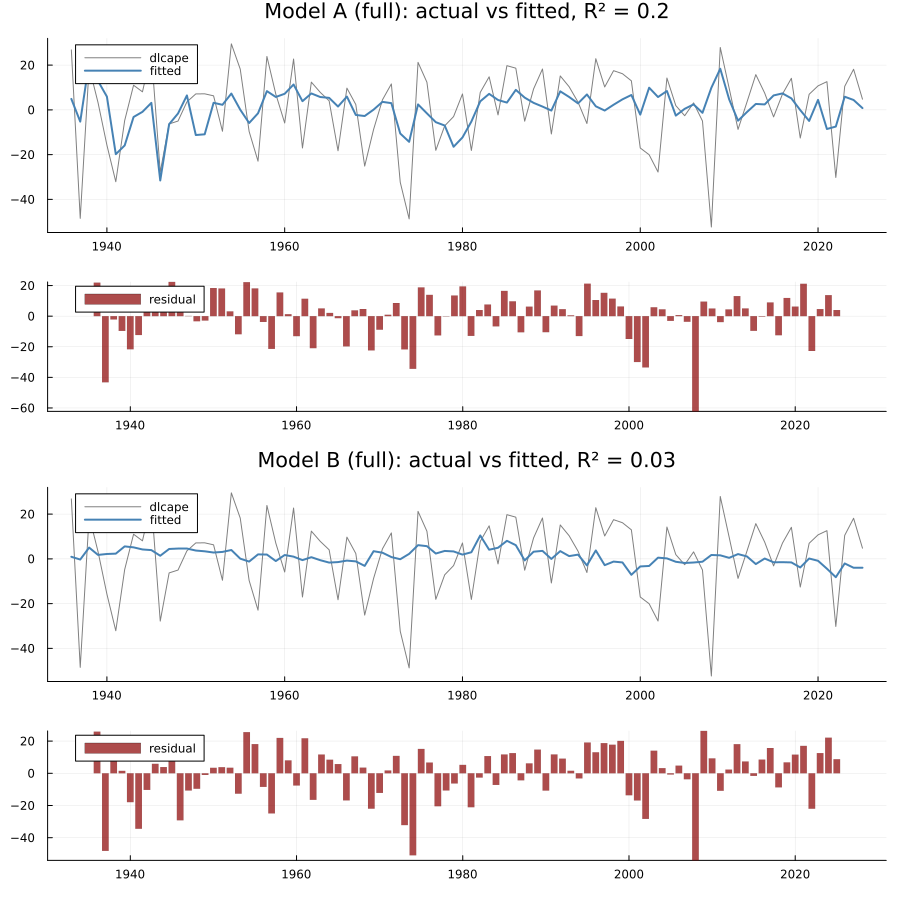

In [16]:
plots_res = map(models) do (m, _)
    fit = fits[(m, :full)]
    p = plot(fit.years, fit.fitted .+ fit.resid; label = "dlcape", lw = 1, color = :gray,
             title = "Model $m (full): actual vs fitted, R² = $(round(fit.r2; digits = 2))")
    plot!(p, fit.years, fit.fitted; label = "fitted", lw = 2, color = :steelblue)
    q = bar(fit.years, fit.resid; label = "residual", lw = 0, color = :darkred, alpha = 0.7)
    [p, q]
end
plot(vcat(plots_res...)...; layout = grid(4, 1; heights = [0.3, 0.2, 0.3, 0.2]), size = (900, 900), legend = :topleft)

### Incremental contribution of each regressor

Drop one regressor at a time and refit: `ΔR²` is the R² lost and `F`, `p` the nested (partial) F-test. With π, r and fr collinear this is more informative than the individual t-tests: a variable can have a small t-stat and still matter jointly with its collinear partner.

In [17]:
incremental = DataFrame([begin
    sub = subperiod(data_lag, p)
    full_fit = fits[(m, name)]
    restricted = fit_ols(sub, filter(!=(v), regs))
    pf = partial_f(full_fit, restricted)
    (model = String(m), period = String(name), dropped = String(v),
     ΔR² = full_fit.r2 - restricted.r2, F = pf.F, p = pf.p)
end for (m, regs) in models for (name, p) in periods for v in regs])
show_table(unstack(incremental, [:model, :dropped], :period, :ΔR²); title = "ΔR² from dropping each regressor")
show_table(incremental; title = "Nested F-tests (drop one regressor)")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"5\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">ΔR² from dropping each regressor</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">model</th>\n      <th style = \"font-weight: bold; text-align: right;\">dropped</th>\n      <th style = \"font-weight: bold; text-align: right;\">full</th>\n      <th style = \"font-weight: bold; text-align: right;\">pre1975</th>\n      <th style = \"font-weight: bold; text-align: right;\">post1975</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64?</th>\n      <th style = \"text-align: right;\">Float64?</th>\n      <th style = \"text-align: right;\">Float64?</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.12</td>\n      <td style = \"text-align: right;\">0.0</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.05</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.02</td>\n      <td style = \"text-align: right;\">0.0</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">fr</td>\n      <td style = \"text-align: right;\">0.04</td>\n      <td style = \"text-align: right;\">0.05</td>\n      <td style = \"text-align: right;\">0.03</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.02</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">B</td>\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">B</td>\n      <td style = \"text-align: right;\">logcape_lag</td>\n      <td style = \"text-align: right;\">0.02</td>\n      <td style = \"text-align: right;\">0.08</td>\n      <td style = \"text-align: right;\">0.03</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">B</td>\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n  </tbody>\n</table>\n")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"6\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Nested F-tests (drop one regressor)</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">model</th>\n      <th style = \"font-weight: bold; text-align: right;\">period</th>\n      <th style = \"font-weight: bold; text-align: right;\">dropped</th>\n      <th style = \"font-weight: bold; text-align: right;\">ΔR²</th>\n      <th style = \"font-weight: bold; text-align: right;\">F</th>\n      <th style = \"font-weight: bold; text-align: right;\">p</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.95</td>\n      <td style = \"text-align: right;\">0.33</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.92</td>\n      <td style = \"text-align: right;\">0.34</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.0</td>\n      <td style = \"text-align: right;\">0.48</td>\n      <td style = \"text-align: right;\">0.49</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">fr</td>\n      <td style = \"text-align: right;\">0.04</td>\n      <td style = \"text-align: right;\">3.71</td>\n      <td style = \"text-align: right;\">0.06</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">full</td>\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">0.01</td>\n      <td style = \"text-align: right;\">0.93</td>\n      <td style = \"text-align: right;\">0.34</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">π</td>\n      <td style = \"text-align: right;\">0.12</td>\n      <td style = \"text-align: right;\">6.82</td>\n      <td style = \"text-align: right;\">0.01</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">r</td>\n      <td style = \"text-align: right;\">0.05</td>\n      <td style = \"text-align: right;\">2.9</td>\n      <td style = \"text-align: right;\">0.1</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">pre1975</td>\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">0.02</td>\n      <td style = \"text-align: right;\">1.43</td>\n      <td style = \"text-align: right;\">0.24</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">pre

### Stability: Chow test at 1975

H0: the same coefficients in 1936–1974 and 1975–2025. $F = \dfrac{(SSR_{full} - SSR_{pre} - SSR_{post})/k}{(SSR_{pre} + SSR_{post})/(n - 2k)}$ (homoskedastic version).

In [18]:
chow = DataFrame(map(models) do (m, _)
    f, a, b = fits[(m, :full)], fits[(m, :pre1975)], fits[(m, :post1975)]
    k = f.k
    ssr_u = a.ssr + b.ssr
    F = ((f.ssr - ssr_u) / k) / (ssr_u / (f.n - 2k))
    (model = String(m), k = k, n = f.n, F = F, p = ccdf(FDist(k, f.n - 2k), F))
end)
show_table(chow; title = "Chow test, break in 1975")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"5\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Chow test, break in 1975</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">model</th>\n      <th style = \"font-weight: bold; text-align: right;\">k</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">F</th>\n      <th style = \"font-weight: bold; text-align: right;\">p</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">A</td>\n      <td style = \"text-align: right;\">6.0</td>\n      <td style = \"text-align: right;\">90.0</td>\n      <td style = \"text-align: right;\">1.45</td>\n      <td style = \"text-align: right;\">0.21</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">B</td>\n      <td style = \"text-align: right;\">4.0</td>\n      <td style = \"text-align: right;\">90.0</td>\n      <td style = \"text-align: right;\">1.21</td>\n      <td style = \"text-align: right;\">0.31</td>\n    </tr>\n  </tbody>\n</table>\n")

### Out-of-sample predictability (Model B and its components)

Expanding window: for each year $t$ from 1965, fit on 1936…$t-1$ and forecast $dlcape_t$; the benchmark is the historical mean of `dlcape` over the same window. $R^2_{OS} = 1 - \sum (y - \hat y)^2 / \sum (y - \bar y)^2$ (Campbell–Thompson); $R^2_{OS} > 0$ means the predictor beats the mean. `CW` is the Clark–West MSPE-adjusted t-statistic (one-sided, H0: no predictability), the appropriate test for nested models.

Only the predictive regressors are used; Model A's contemporaneous variables are not known at forecast time.

In [19]:
function oos_forecast(ta, regs; first_year = 1965)
    yrs = year.(timestamp(ta))
    z = col(ta, :dlcape)
    X = hcat(ones(length(z)), (col(ta, r) for r in regs)...)
    out = [begin
        train = yrs .< t
        i = findfirst(==(t), yrs)
        β = X[train, :] \ z[train]
        (year = t, y = z[i], model = dot(X[i, :], β), mean = mean(z[train]))
    end for t in yrs if t >= first_year]
    return DataFrame(out)
end

oos_specs = [
    "B: tp + logcape_lag + dlcape_lag" => [:tp, :logcape_lag, :dlcape_lag],
    "tp"                               => [:tp],
    "logcape_lag"                      => [:logcape_lag],
    "dlcape_lag"                       => [:dlcape_lag],
]
oos = Dict(label => oos_forecast(data_lag, regs) for (label, regs) in oos_specs)

oos_table = DataFrame(map(oos_specs) do (label, _)
    d = oos[label]
    e_m, e_b = d.y .- d.model, d.y .- d.mean
    f = e_b .^ 2 .- (e_m .^ 2 .- (d.mean .- d.model) .^ 2)
    cw = mean(f) / (std(f) / sqrt(length(f)))
    (predictor = label, years = "$(d.year[1])–$(d.year[end])", n = nrow(d),
     R²_OS = 1 - sum(abs2, e_m) / sum(abs2, e_b), CW = cw, p_CW = ccdf(TDist(length(f) - 1), cw))
end)
show_table(oos_table; title = "Out-of-sample R² vs the historical mean")

HTML{String}("<table>\n  <thead>\n    <tr class = \"title\">\n      <td colspan = \"6\" style = \"font-size: x-large; font-weight: bold; text-align: center;\">Out-of-sample R² vs the historical mean</td>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"font-weight: bold; text-align: right;\">predictor</th>\n      <th style = \"font-weight: bold; text-align: right;\">years</th>\n      <th style = \"font-weight: bold; text-align: right;\">n</th>\n      <th style = \"font-weight: bold; text-align: right;\">R²_OS</th>\n      <th style = \"font-weight: bold; text-align: right;\">CW</th>\n      <th style = \"font-weight: bold; text-align: right;\">p_CW</th>\n    </tr>\n    <tr class = \"columnLabelRow\">\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">String</th>\n      <th style = \"text-align: right;\">Int64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n      <th style = \"text-align: right;\">Float64</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">B: tp + logcape_lag + dlcape_lag</td>\n      <td style = \"text-align: right;\">1965–2025</td>\n      <td style = \"text-align: right;\">61.0</td>\n      <td style = \"text-align: right;\">-0.15</td>\n      <td style = \"text-align: right;\">-0.05</td>\n      <td style = \"text-align: right;\">0.52</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">tp</td>\n      <td style = \"text-align: right;\">1965–2025</td>\n      <td style = \"text-align: right;\">61.0</td>\n      <td style = \"text-align: right;\">-0.08</td>\n      <td style = \"text-align: right;\">-0.25</td>\n      <td style = \"text-align: right;\">0.6</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">logcape_lag</td>\n      <td style = \"text-align: right;\">1965–2025</td>\n      <td style = \"text-align: right;\">61.0</td>\n      <td style = \"text-align: right;\">-0.05</td>\n      <td style = \"text-align: right;\">0.93</td>\n      <td style = \"text-align: right;\">0.18</td>\n    </tr>\n    <tr class = \"dataRow\">\n      <td style = \"text-align: right;\">dlcape_lag</td>\n      <td style = \"text-align: right;\">1965–2025</td>\n      <td style = \"text-align: right;\">61.0</td>\n      <td style = \"text-align: right;\">-0.04</td>\n      <td style = \"text-align: right;\">-0.98</td>\n      <td style = \"text-align: right;\">0.83</td>\n    </tr>\n  </tbody>\n</table>\n")

Cumulative difference in squared errors, mean minus model (Goyal–Welch plot): rising means the predictor is beating the historical mean in that period.

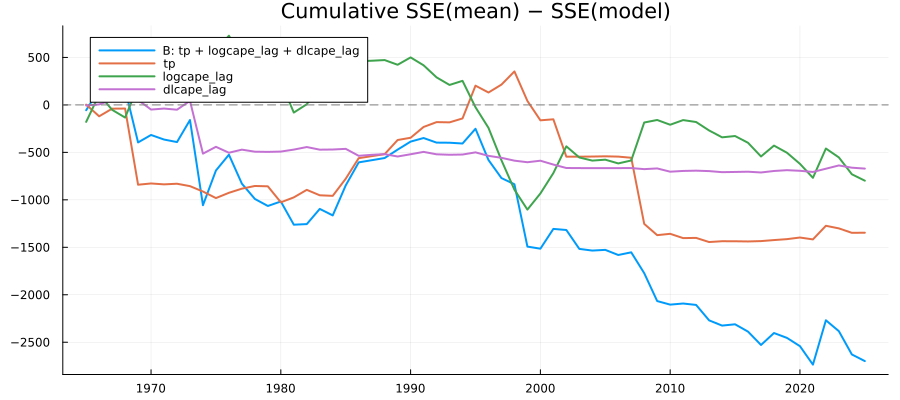

In [20]:
p = plot(title = "Cumulative SSE(mean) − SSE(model)", size = (900, 400), legend = :topleft)
for (label, _) in oos_specs
    d = oos[label]
    plot!(p, d.year, cumsum((d.y .- d.mean) .^ 2 .- (d.y .- d.model) .^ 2); label, lw = 2)
end
hline!(p, [0]; color = :gray, ls = :dash, label = "")
p

## 10. Conclusion

*(Numbers from the 1935–2025 data as of this writing; re-check after updating `ie_data.xlsx`.)*

- **dlcape is stationary and close to white noise.** ADF rejects a unit root and KPSS does not reject stationarity in every period; the lag-1 autocorrelation is about −0.06 and `dlcape_lag` is insignificant everywhere. The mean re-rating is +1.3%/yr over 1935–2025 (t ≈ 0.7) and +3.1%/yr after 1975 (t ≈ 1.4): not significantly different from zero, but large enough that removing it from erp (as ISSM does) matters for the level of simulated returns.
- **The valuation level is not demonstrably mean-reverting in this sample.** ADF does not reject a unit root in log CAPE in any period, and KPSS rejects stationarity for the full sample and post-1975. In-sample, `logcape_lag` has the expected negative sign (γ ≈ −0.06 full, −0.23 pre-1975) but Model B has R² ≈ 0.03 and the joint test does not reject unpredictability (p ≈ 0.17). Out of sample every predictive specification has R²_OS < 0 against the historical mean, and Clark–West does not reject. **Treatment 3 is not supported.**
- **The contemporaneous macro link is real but unstable.** Before 1975 inflation shocks explain a third of the re-rating (univariate R² 0.34, Model A R² 0.44, macro terms jointly significant); after 1975 Model A explains about 7% and its macro terms are jointly insignificant (p ≈ 0.28). The Chow test does not reject a common model (p ≈ 0.21), but with ~40–50 years per half it has little power. Part of the `fr` effect is mechanical (shared earnings-growth term); `fr_real` alone explains only about 5%.
- **Implication for ISSM:** treatment 1 is consistent with the evidence. Bootstrapping whole years keeps the same-year correlation between re-rating and inflation / real-rate shocks without a model term, and no predictive term for dlcape is justified. Open choices for the scenarios: which mean to remove (full-sample +1.3% vs post-1975 +3.1%), and whether the bootstrap window should include the pre-1975 years, where the inflation–valuation link is much stronger.